# RabTech Academy – Task 03: Advanced Statistical Analysis & Hypothesis Testing

**Dataset:** UCI Bike Sharing Dataset (`hour.csv`).

This notebook covers Shapiro–Wilk and Kolmogorov–Smirnov-style normality testing (Lilliefors correction), Welch's two-sample t-test, Mann–Whitney U, one-way ANOVA, two-way ANOVA, Tukey HSD, plots, and interpretation.

**Important:** This is observational data. Results describe associations, not causation. The humidity threshold of 0.70 follows the Task 02 preregistration. Treat the remaining tests as additional Task 03 analyses and document any deviations.


## 1. Load the dataset

Download the UCI Bike Sharing Dataset, extract it, and put `hour.csv` in a `data` folder beside the `notebooks` folder:

```text
project/
├── data/hour.csv
└── notebooks/task03_statistical_analysis.ipynb
```


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/hour.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/hour.csv")
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 2. Inspect and clean required fields

Remove exact duplicate rows and rows missing fields needed for these analyses. Do not remove valid high or low rental counts just because they look unusual.


In [2]:
required = ["cnt", "hum", "season", "workingday", "temp", "hr", "weathersit"]
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

print("Missing values:")
display(df[required].isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())

data = df.drop_duplicates().dropna(subset=required).copy()
data = data[data["hum"].between(0, 1) & (data["cnt"] >= 0)].copy()
data["high_humidity"] = (data["hum"] >= 0.70).astype(int)
data["humidity_group"] = np.where(data["high_humidity"].eq(1), "High humidity (≥0.70)", "Lower humidity (<0.70)")
data["season"] = data["season"].astype("category")
data["workingday"] = data["workingday"].astype("category")

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(data))
print("Rows excluded:", len(df) - len(data))
display(data[required].describe(include="all"))


Missing values:


cnt           0
hum           0
season        0
workingday    0
temp          0
hr            0
weathersit    0
dtype: int64

Exact duplicate rows: 0
Rows before cleaning: 17379
Rows after cleaning: 17379
Rows excluded: 0


,cnt,hum,season,workingday,temp,hr,weathersit
count,17379.000000,17379.000000,17379.0,17379.0,17379.000000,17379.000000,17379.000000
unique,NaN,NaN,4.0,2.0,NaN,NaN,NaN
top,NaN,NaN,3.0,1.0,NaN,NaN,NaN
freq,NaN,NaN,4496.0,11865.0,NaN,NaN,NaN
mean,189.463088,0.627229,NaN,NaN,0.496987,11.546752,1.425283
std,181.387599,0.192930,NaN,NaN,0.192556,6.914405,0.639357
min,1.000000,0.000000,NaN,NaN,0.020000,0.000000,1.000000
25%,40.000000,0.480000,NaN,NaN,0.340000,6.000000,1.000000
50%,142.000000,0.630000,NaN,NaN,0.500000,12.000000,1.000000
75%,281.000000,0.780000,NaN,NaN,0.660000,18.000000,2.000000


## 3. Descriptive statistics and plots



,count,mean,median,std,min,max
humidity_group,,,,,,
High humidity (≥0.70),6889,129.204529,75.0,148.481141,1,856
Lower humidity (<0.70),10490,229.036130,190.0,189.952113,1,977


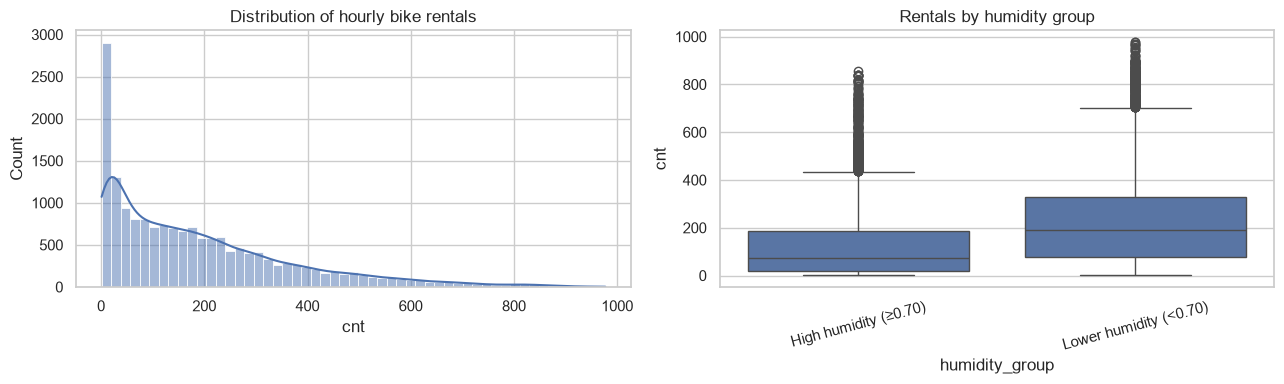

In [3]:
display(data.groupby("humidity_group", observed=False)["cnt"].agg(["count", "mean", "median", "std", "min", "max"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data["cnt"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of hourly bike rentals")
sns.boxplot(data=data, x="humidity_group", y="cnt", ax=axes[1])
axes[1].set_title("Rentals by humidity group")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


## 4. Normality tests

**H0:** The sample is consistent with a normal distribution.  
**H1:** The sample is not consistent with a normal distribution.

Shapiro–Wilk is applied to a reproducible sample of at most 5,000 observations because the dataset is large. For the KS normality test, use the Lilliefors correction because the normal mean and standard deviation are estimated from the sample. A p-value below 0.05 is evidence against normality. Also inspect the histogram and Q-Q plot; large samples can make tests detect minor deviations.


,Test,Statistic,p-value
0,"Shapiro-Wilk (sample ≤ 5,000)",0.873387,2.903896e-53
1,Lilliefors-corrected KS,0.149401,1.000000e-03


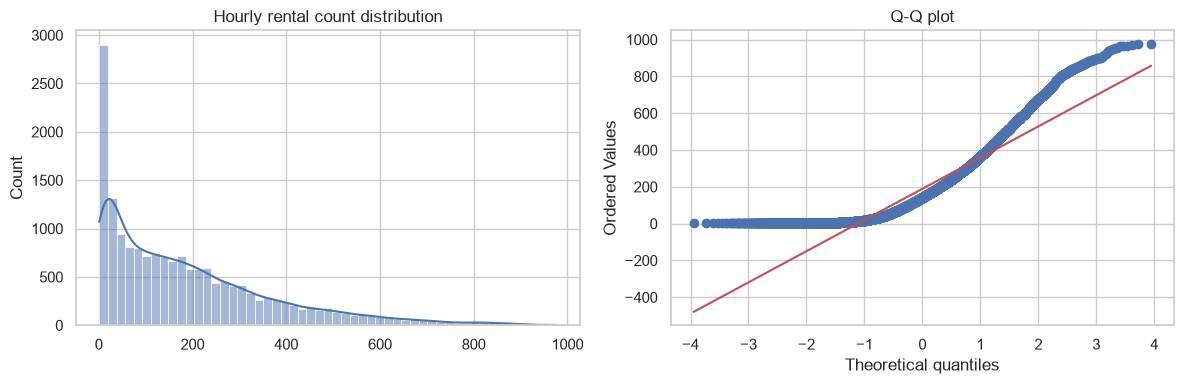

In [4]:
rng = np.random.default_rng(42)
values = data["cnt"].astype(float).to_numpy()
shapiro_values = values if len(values) <= 5000 else rng.choice(values, 5000, replace=False)
shapiro_stat, shapiro_p = stats.shapiro(shapiro_values)
ks_stat, ks_p = lilliefors(values, dist="norm")

display(pd.DataFrame({
    "Test": ["Shapiro-Wilk (sample ≤ 5,000)", "Lilliefors-corrected KS"],
    "Statistic": [shapiro_stat, ks_stat],
    "p-value": [shapiro_p, ks_p]
}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(values, kde=True, ax=axes[0])
axes[0].set_title("Hourly rental count distribution")
stats.probplot(values, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot")
plt.tight_layout()
plt.show()


## 5. Two-sample tests: high vs lower humidity

Compare `hum ≥ 0.70` with `hum < 0.70`, using hourly rental count `cnt`.

**H0 (t-test):** The two groups have equal mean rental counts.  
**H1:** The high-humidity group has a lower mean rental count.

Welch's t-test does not assume equal variances. Mann–Whitney U is a rank-based test of distributions; it is not automatically a test of medians unless distribution shapes are similar.


In [5]:
high = data.loc[data.high_humidity == 1, "cnt"].astype(float)
low = data.loc[data.high_humidity == 0, "cnt"].astype(float)

t_stat, t_p = stats.ttest_ind(high, low, equal_var=False, alternative="two-sided")
u_stat, u_p = stats.mannwhitneyu(high, low, alternative="two-sided")

difference = high.mean() - low.mean()
se = np.sqrt(high.var(ddof=1)/len(high) + low.var(ddof=1)/len(low))
welch_df = (high.var(ddof=1)/len(high) + low.var(ddof=1)/len(low))**2 / (
    (high.var(ddof=1)/len(high))**2/(len(high)-1) +
    (low.var(ddof=1)/len(low))**2/(len(low)-1)
)
margin = stats.t.ppf(0.975, welch_df) * se

display(pd.DataFrame({
    "Test": ["Welch two-sample t-test", "Mann–Whitney U"],
    "Statistic": [t_stat, u_stat],
    "Two-sided p-value": [t_p, u_p]
}))
print(f"High humidity: n={len(high)}, mean={high.mean():.2f}")
print(f"Lower humidity: n={len(low)}, mean={low.mean():.2f}")
print(f"Mean difference (high - lower): {difference:.2f}")
print(f"95% CI for mean difference: ({difference-margin:.2f}, {difference+margin:.2f})")


,Test,Statistic,Two-sided p-value
0,Welch two-sample t-test,-3.874245e+01,0.0
1,Mann–Whitney U,2.339013e+07,0.0


High humidity: n=6889, mean=129.20
Lower humidity: n=10490, mean=229.04
Mean difference (high - lower): -99.83
95% CI for mean difference: (-104.88, -94.78)


## 6. One-Way ANOVA: rental counts across seasons

**H0:** Mean rental counts are equal across all seasons.  
**H1:** At least one season has a different mean.

If the omnibus ANOVA is significant, Tukey HSD identifies which season pairs differ.


One-Way ANOVA F-statistic: 409.1810
p-value: 7.40107e-257


,sum_sq,df,F,PR(>F)
C(season),3.772936e+07,3.0,409.181037,7.401071e-257
Residual,5.340322e+08,17375.0,NaN,NaN


 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
     1      2  97.2295    0.0   87.542  106.917   True
     1      3 124.9017    0.0 115.2603 134.5431   True
     1      4  87.7543    0.0   77.968  97.5406   True
     2      3  27.6722    0.0  18.1252  37.2192   True
     2      4  -9.4752 0.0582 -19.1685   0.2181  False
     3      4 -37.1474    0.0 -46.7946 -27.5001   True
------------------------------------------------------


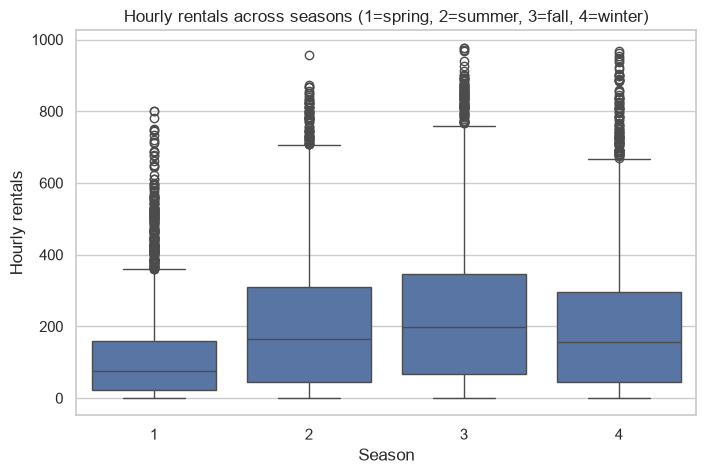

In [6]:
season_groups = [g["cnt"].to_numpy() for _, g in data.groupby("season", observed=True)]
f_stat, f_p = stats.f_oneway(*season_groups)
print(f"One-Way ANOVA F-statistic: {f_stat:.4f}")
print(f"p-value: {f_p:.6g}")

oneway_model = ols("cnt ~ C(season)", data=data).fit()
display(anova_lm(oneway_model, typ=2))

tukey = pairwise_tukeyhsd(data["cnt"], data["season"].astype(str), alpha=0.05)
print(tukey)

plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="season", y="cnt")
plt.title("Hourly rentals across seasons (1=spring, 2=summer, 3=fall, 4=winter)")
plt.xlabel("Season")
plt.ylabel("Hourly rentals")
plt.show()


## 7. Two-Way ANOVA: season × working-day status

**H0 season:** Mean rental counts do not differ by season.  
**H0 working day:** Mean rental counts do not differ by working-day status.  
**H0 interaction:** The season association does not vary by working-day status.

The factorial model includes the interaction term. We use Type II ANOVA.


,sum_sq,df,F,PR(>F)
C(season),3.748219e+07,3.0,407.014449,1.544102e-255
C(workingday),2.772180e+05,1.0,9.030828,2.658430e-03
C(season):C(workingday),5.199753e+05,3.0,5.646347,7.301192e-04
Residual,5.332350e+08,17371.0,NaN,NaN


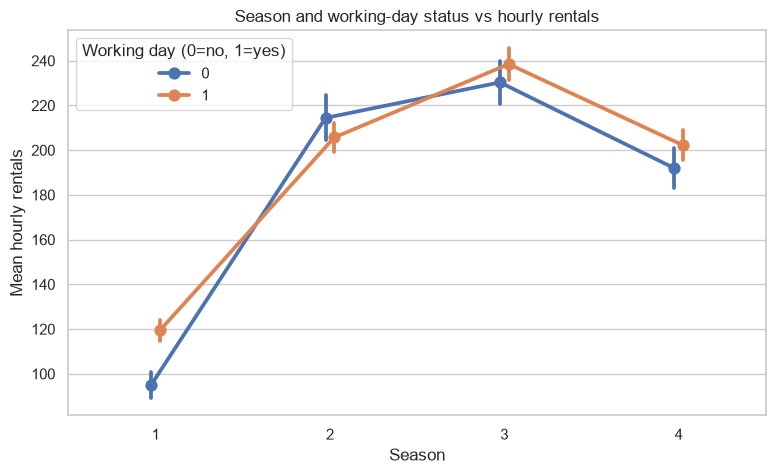

In [7]:
two_way_model = ols("cnt ~ C(season) * C(workingday)", data=data).fit()
two_way_table = anova_lm(two_way_model, typ=2)
display(two_way_table)

plt.figure(figsize=(9, 5))
sns.pointplot(data=data, x="season", y="cnt", hue="workingday", errorbar=("ci", 95), dodge=True)
plt.title("Season and working-day status vs hourly rentals")
plt.xlabel("Season")
plt.ylabel("Mean hourly rentals")
plt.legend(title="Working day (0=no, 1=yes)")
plt.show()


## 8. Model diagnostics

ANOVA assumes independent observations, approximately normal residuals within groups, and reasonably similar variances. Hourly records are time-ordered, so independence may be violated; mention this limitation.


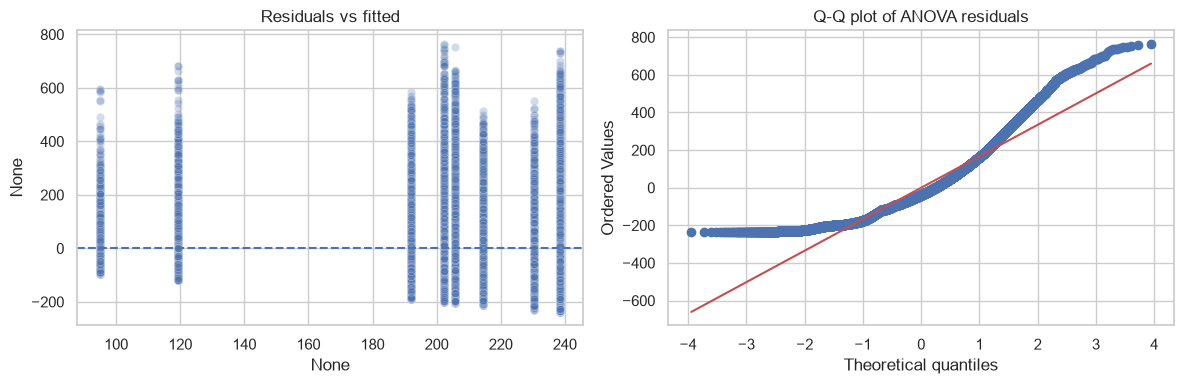

In [8]:
residuals = two_way_model.resid
fitted = two_way_model.fittedvalues
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(x=fitted, y=residuals, alpha=0.25, ax=axes[0])
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Residuals vs fitted")
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot of ANOVA residuals")
plt.tight_layout()
plt.show()


## 9. Findings and conclusion – complete after running all cells

Use the actual outputs above; do not invent results.

1. **Normality:** Report Shapiro–Wilk and Lilliefors-corrected KS statistics and p-values. Describe histogram and Q-Q plot.
2. **Humidity comparison:** Report group sizes and means, Welch t statistic and p-value, Mann–Whitney U statistic and p-value, and 95% CI for the mean difference.
3. **One-Way ANOVA:** Report F-statistic and p-value. If significant, summarise Tukey HSD pairwise results.
4. **Two-Way ANOVA:** Report season, working-day and interaction results.
5. **Limitations:** Observational data, one bike-sharing system and period, possible serial correlation in hourly records, and potential confounding.

**Decision rule:** At α = 0.05, if p < 0.05 reject the relevant null hypothesis; otherwise fail to reject it. Do not write “accept the null hypothesis.”


## 10. Reproducibility: software versions



In [9]:
import sys, scipy, statsmodels, matplotlib, seaborn
print("Python:", sys.version)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("statsmodels:", statsmodels.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", seaborn.__version__)


Python: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
pandas: 3.1.1
NumPy: 2.5.4
SciPy: 1.18.1
statsmodels: 0.15.0
Matplotlib: 3.11.2
Seaborn: 0.13.2
